# Semana 10 — entrenamiento local con GPU

Este cuaderno ejecuta el flujo principal de la Semana 10 sin depender de Colab ni de Kaggle:

1. comprueba el entorno y la GPU;
2. construye o reutiliza el caché de 384×384;
3. entrena el modelo multitarea;
4. muestra el historial y las mejores métricas;
5. evalúa uno o todos los volúmenes de validación;
6. compara la corrida local con el H6 oficial incluido en el repositorio.

> **Empieza con `MODO_RAPIDO = True`.** Cuando ese ensayo termine correctamente, cambia a `False` para lanzar la receta completa H6. La receta completa está pensada para GPU y puede tardar cerca de tres horas, dependiendo del equipo.

## 0. Preparación del entorno

Se recomienda Python 3.11 o 3.12. Abre Jupyter desde la raíz del repositorio:

```powershell
cd E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main
jupyter lab notebooks/06_semana10_entrenamiento_local_gpu.ipynb
```

Antes de ejecutar el cuaderno, instala una compilación de PyTorch compatible con tu GPU NVIDIA y después las dependencias del proyecto. El comando exacto de PyTorch depende del controlador y de la versión CUDA de tu equipo. La celda siguiente **no reinstala PyTorch automáticamente**, para no sustituir accidentalmente una instalación GPU por una instalación CPU.

In [30]:
# Localizar la raíz del repositorio aunque el notebook se abra desde notebooks/.
import os
import sys
from pathlib import Path

def encontrar_raiz(inicio: Path) -> Path:
    for candidato in (inicio, *inicio.parents):
        if (candidato / 'src' / 'train_s10.py').exists() and (candidato / 'README.md').exists():
            return candidato
    raise FileNotFoundError('No encontré la raíz del repositorio. Inicia Jupyter dentro del proyecto.')

ROOT = encontrar_raiz(Path.cwd().resolve())
os.chdir(ROOT)
os.environ['PYTHONUTF8'] = '1'  # evita errores de consola cp1252 en Windows
print('Raíz:', ROOT)
print('Python:', sys.version.split()[0], '| ejecutable:', sys.executable)

Raíz: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main
Python: 3.12.6 | ejecutable: e:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\.venv\Scripts\python.exe


In [31]:
# Opcional: instala las dependencias generales, pero conserva la instalación actual de torch.
INSTALAR_DEPENDENCIAS = False

if INSTALAR_DEPENDENCIAS:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', str(ROOT / 'requirements.txt')], check=True)
else:
    print('Instalación omitida. Cambia INSTALAR_DEPENDENCIAS=True si todavía faltan paquetes.')

Instalación omitida. Cambia INSTALAR_DEPENDENCIAS=True si todavía faltan paquetes.


## 1. Configuración de la corrida

El modo rápido entrena una red pequeña durante dos épocas y evalúa un solo caso. Sirve únicamente para comprobar que GPU, datos, caché y scripts funcionan. Con `MODO_RAPIDO = False` se usa la receta final H6 de la Semana 10.

Las salidas locales se guardan en `outputs/s10/local_gpu/`, por lo que no se sobrescriben los resultados oficiales del repositorio.

In [32]:
MODO_RAPIDO = False
EXIGIR_GPU = True
CONSTRUIR_CACHE_SI_FALTA = True
EJECUTAR_ENTRENAMIENTO = True
EJECUTAR_EVALUACION = True
EXPORTAR_DEMO = False  # opcional: prepara un caso para verlo en Streamlit
CASO_DEMO = '024'
BATCH_SIZE_H6 = 2  # seguro para la GTX 1650 SUPER de 4 GB; 16 reproduce la receta original en una L4

CACHE_ROOT = ROOT / 'data' / 'cache' / 's10'
CACHE_DIR = CACHE_ROOT / 'cache_384'
SALIDA_DIR = ROOT / 'outputs' / 's10' / 'local_gpu'
SALIDA_DIR.mkdir(parents=True, exist_ok=True)

if MODO_RAPIDO:
    NOMBRE = 'smoke_semana10_gpu'
    EPOCHS = 2
    BASE_CHANNELS = 8
    BATCH_SIZE = 4
    PER_EPOCH = 100
    EVAL_EVERY = 1
    MAX_MINUTES = 15
    CASOS_EVALUACION = ['014']
else:
    NOMBRE = 'h6_auggeo_rot35_canon_ema_w32_e60_s42_local'
    EPOCHS = 60
    BASE_CHANNELS = 32
    BATCH_SIZE = BATCH_SIZE_H6
    PER_EPOCH = 2500
    EVAL_EVERY = 10
    MAX_MINUTES = 170
    CASOS_EVALUACION = []  # vacío = los 15 casos de validación

CHECKPOINT = SALIDA_DIR / f'{NOMBRE}.pth'
HISTORIAL_JSON = CHECKPOINT.with_suffix('.json')
VALIDACION_JSON = SALIDA_DIR / f'{NOMBRE}_val.json'
LOG_ENTRENAMIENTO = SALIDA_DIR / f'{NOMBRE}_train.log'
LOG_EVALUACION = SALIDA_DIR / f'{NOMBRE}_eval.log'

print('Modo:', 'RÁPIDO' if MODO_RAPIDO else 'H6 COMPLETO')
print('Checkpoint:', CHECKPOINT)
print('Evaluación:', 'caso ' + ', '.join(CASOS_EVALUACION) if CASOS_EVALUACION else 'validación completa')
print('Batch size:', BATCH_SIZE)

Modo: H6 COMPLETO
Checkpoint: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\local_gpu\h6_auggeo_rot35_canon_ema_w32_e60_s42_local.pth
Evaluación: validación completa
Batch size: 2


### Resultados oficiales disponibles sin entrenar

Esta celda permite comprobar desde el principio qué resultado debería aproximar una corrida H6 completa. No necesita GPU, datos crudos ni caché.

In [33]:
import json
import pandas as pd

OFICIAL_JSON = ROOT / 'outputs' / 's10' / 'h6_auggeo_rot35_canon_ema_w32_e60_s42_val.json'
if OFICIAL_JSON.exists():
    oficial_previo = json.loads(OFICIAL_JSON.read_text(encoding='utf-8'))
    claves_principales = [
        'classification_f1_macro', 'classification_auc_macro', 'detection_iou_mean',
        'detection_map50', 'detection_map50_95', 'segmentation_dice_macro',
        'segmentation_iou_macro', 'instance_dice_matched', 'instance_iou_matched',
    ]
    resumen_oficial_previo = oficial_previo['subsets']['todo']
    display(pd.DataFrame({
        'métrica': claves_principales,
        'H6 oficial (validación)': [resumen_oficial_previo.get(k) for k in claves_principales],
    }).round(4))
else:
    print('No se encontró el resultado oficial:', OFICIAL_JSON)

,métrica,H6 oficial (validación)
0,classification_f1_macro,0.9920
1,classification_auc_macro,0.9994
2,detection_iou_mean,0.9492
3,detection_map50,0.9711
4,detection_map50_95,0.9038
5,segmentation_dice_macro,0.9714
6,segmentation_iou_macro,0.9445
7,instance_dice_matched,0.8694
8,instance_iou_matched,0.8083


## 2. Comprobar GPU y dependencias

Si `CUDA disponible` aparece como `False`, detén el cuaderno y corrige la instalación de PyTorch. El entrenamiento puede ejecutarse en CPU, pero no es una opción práctica para la receta completa.

In [34]:
import importlib

requeridos = ['numpy', 'pandas', 'matplotlib', 'scipy', 'skimage', 'SimpleITK', 'torch']
faltantes = []
for modulo in requeridos:
    try:
        importlib.import_module(modulo)
    except ImportError:
        faltantes.append(modulo)
if faltantes:
    raise RuntimeError(f'Faltan dependencias: {faltantes}. Activa INSTALAR_DEPENDENCIAS y repite.')

import torch
print('PyTorch:', torch.__version__)
print('CUDA de PyTorch:', torch.version.cuda)
print('CUDA disponible:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    props = torch.cuda.get_device_properties(0)
    vram_gb = props.total_memory / 1024**3
    print(f'Memoria GPU: {vram_gb:.1f} GB')
    if not MODO_RAPIDO and vram_gb < 10:
        print('AVISO: VRAM limitada. Se recomienda BATCH_SIZE_H6=2; el lote 16 original necesita una GPU mayor.')
else:
    mensaje = 'PyTorch no detecta una GPU CUDA. Instala la variante CUDA adecuada antes de entrenar.'
    if EXIGIR_GPU:
        raise RuntimeError(mensaje)
    print('ADVERTENCIA:', mensaje)

PyTorch: 2.11.0+cu128
CUDA de PyTorch: 12.8
CUDA disponible: True
GPU: NVIDIA GeForce GTX 1650 SUPER
Memoria GPU: 4.0 GB
AVISO: VRAM limitada. Se recomienda BATCH_SIZE_H6=2; el lote 16 original necesita una GPU mayor.


In [35]:
# Ayudante para mostrar en vivo la salida de los scripts dentro del notebook.
import subprocess
import time
from collections import deque

def ejecutar_visible(comando: list[str], titulo: str, log_path: Path | None = None) -> None:
    print(f'\n=== {titulo} ===')
    print(' '.join(map(str, comando)))
    entorno = os.environ.copy()
    entorno['PYTHONUTF8'] = '1'
    inicio = time.perf_counter()
    proceso = subprocess.Popen(
        comando, cwd=ROOT, env=entorno, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, encoding='utf-8', errors='replace', bufsize=1
    )
    assert proceso.stdout is not None
    log = None
    if log_path is not None:
        log_path.parent.mkdir(parents=True, exist_ok=True)
        log = log_path.open('w', encoding='utf-8')
        log.write('$ ' + ' '.join(map(str, comando)) + '\n\n')
    ultimas_lineas = deque(maxlen=25)
    try:
        for linea in proceso.stdout:
            print(linea, end='')
            ultimas_lineas.append(linea.rstrip())
            if log is not None:
                log.write(linea)
                log.flush()
    except KeyboardInterrupt:
        proceso.terminate()
        proceso.wait(timeout=15)
        print('\nProceso interrumpido por el usuario.')
        raise
    finally:
        if log is not None:
            log.close()
    codigo = proceso.wait()
    minutos = (time.perf_counter() - inicio) / 60
    print(f'=== finalizó con código {codigo} en {minutos:.1f} min ===')
    if log_path is not None:
        print('Log:', log_path)
    if codigo != 0:
        detalle = '\n'.join(ultimas_lineas)
        raise RuntimeError(f'El comando terminó con código {codigo}. Últimas líneas:\n{detalle}')

## 3. Preparar o reutilizar el caché

Para construirlo deben existir los 100 volúmenes y sus etiquetas bajo `data/raw/`, con la estructura indicada en el README. Si ya existe `data/cache/s10/cache_384`, la celda lo reutiliza.

In [36]:
casos_cache = sorted(CACHE_DIR.glob('*.npz')) if CACHE_DIR.exists() else []
print(f'Caché actual: {len(casos_cache)} casos en {CACHE_DIR}')

if len(casos_cache) < 100:
    if not CONSTRUIR_CACHE_SI_FALTA:
        raise FileNotFoundError('El caché no está completo y CONSTRUIR_CACHE_SI_FALTA=False.')
    raw_root = ROOT / 'data' / 'raw'
    imagenes = list(raw_root.glob('PENGWIN_CT_train_images_part*/*.mha'))
    etiquetas = list((raw_root / 'PENGWIN_CT_train_labels').glob('*.mha'))
    print(f'Datos crudos encontrados: {len(imagenes)} imágenes y {len(etiquetas)} etiquetas')
    if len(imagenes) < 100 or len(etiquetas) < 100:
        raise FileNotFoundError(
            'Faltan los datos PENGWIN en data/raw. Consulta la sección Datos del README antes de continuar.'
        )
    ejecutar_visible([
        sys.executable, 'src/build_case_cache.py',
        '--sizes', '384', '--modes', 'stretch', '--workers', '4'
    ], 'Construcción del caché 384')
    casos_cache = sorted(CACHE_DIR.glob('*.npz'))

if len(casos_cache) < 100:
    raise RuntimeError(f'El caché quedó incompleto: {len(casos_cache)}/100 casos.')
print(f'Caché listo: {len(casos_cache)} casos.')

Caché actual: 100 casos en E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\s10\cache_384
Caché listo: 100 casos.


## 4. Entrenar

La salida de cada época aparece debajo de la celda. `train_s10.py` guarda automáticamente el mejor checkpoint y un JSON con el historial.

In [37]:
comando_entrenamiento = [
    sys.executable, 'src/train_s10.py',
    '--cache-root', str(CACHE_ROOT),
    '--size', '384',
    '--epochs', str(EPOCHS),
    '--base-channels', str(BASE_CHANNELS),
    '--cbam', '1',
    '--disable-cudnn',
    '--secondary-weight', '3',
    '--augment', '--cosine',
    '--batch-size', str(BATCH_SIZE),
    '--per-epoch', str(PER_EPOCH),
    '--max-minutes', str(MAX_MINUTES),
    '--eval-every', str(EVAL_EVERY),
    '--ema', '0.999',
    '--seed', '42',
    '--aug-geo', '1.0',
    '--aug-rot-deg', '35',
    '--canonical',
    '--output', str(CHECKPOINT),
]

if EJECUTAR_ENTRENAMIENTO:
    ejecutar_visible(comando_entrenamiento, 'Entrenamiento Semana 10', LOG_ENTRENAMIENTO)
elif CHECKPOINT.exists():
    print('Entrenamiento omitido; se reutilizará:', CHECKPOINT)
else:
    raise FileNotFoundError('EJECUTAR_ENTRENAMIENTO=False y no existe el checkpoint configurado.')


=== Entrenamiento Semana 10 ===
e:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\.venv\Scripts\python.exe src/train_s10.py --cache-root E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\s10 --size 384 --epochs 60 --base-channels 32 --cbam 1 --secondary-weight 3 --augment --cosine --batch-size 2 --per-epoch 2500 --max-minutes 170 --eval-every 10 --ema 0.999 --seed 42 --aug-geo 1.0 --aug-rot-deg 35 --canonical --output E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\local_gpu\h6_auggeo_rot35_canon_ema_w32_e60_s42_local.pth
Casos: train=70 val=15 | E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\s10\cache_384
Cortes train=18266 (con hueso 16876) | val=709 | carga 81s
Modelo: 2,736,958 parámetros | CBAM=1 γ aprendible=False | cuda
epoch 001 loss=nan dice=0.0000 map50=0.0000 inst=0.0000 (637s/época, total 12.2 min)
epoch 002 loss=nan (317s)
epoch 003 loss=nan (308s)
epoch 004 loss=nan (304s)
epoch 005 loss=nan (301s)
epoch 006 loss

## 5. Ver las salidas del entrenamiento

,epoch,loss,score,classification_f1_macro,classification_auc_macro,detection_iou_mean,detection_map50,detection_map50_95,segmentation_dice_macro,segmentation_iou_macro,instance_dice_matched,instance_iou_matched,instance_semantic_cc_dice_matched,instance_semantic_cc_iou_matched,instance_direct_dice_matched,instance_direct_iou_matched
0,1,NaN,0.0,0.0,0.4771,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,10,NaN,0.0,0.0,0.4771,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,20,NaN,0.0,0.0,0.4771,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,30,NaN,0.0,0.0,0.4771,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


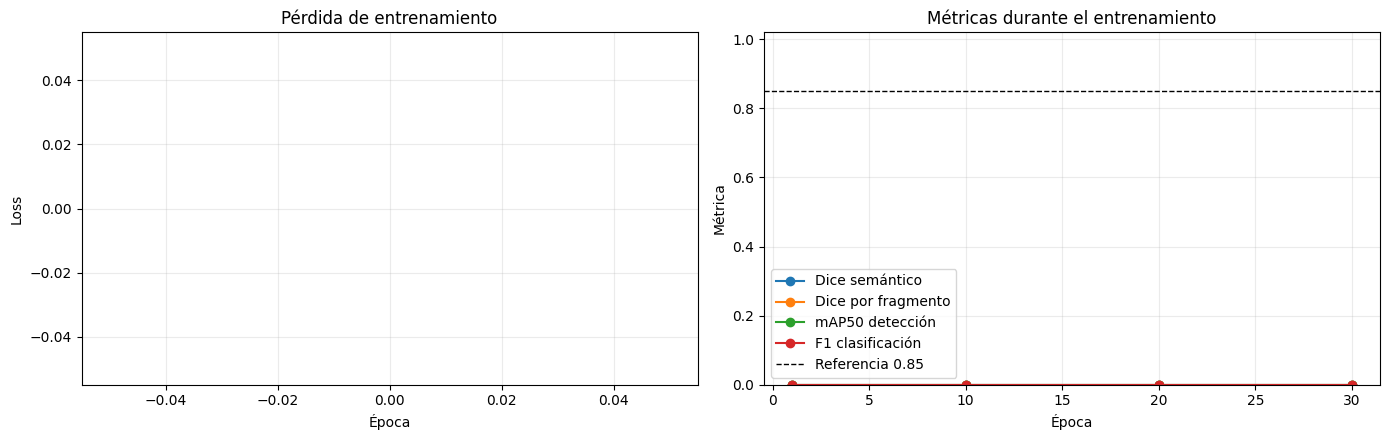

In [38]:
import json
import matplotlib.pyplot as plt
import pandas as pd

if not HISTORIAL_JSON.exists():
    raise FileNotFoundError(f'No existe el historial: {HISTORIAL_JSON}')

entrenamiento = json.loads(HISTORIAL_JSON.read_text(encoding='utf-8'))
historial = pd.DataFrame(entrenamiento['history'])
display(historial.round(4))

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
ejes[0].plot(historial['epoch'], historial['loss'], marker='o')
ejes[0].set(title='Pérdida de entrenamiento', xlabel='Época', ylabel='Loss')
ejes[0].grid(alpha=.25)

metricas_curva = {
    'segmentation_dice_macro': 'Dice semántico',
    'instance_dice_matched': 'Dice por fragmento',
    'detection_map50': 'mAP50 detección',
    'classification_f1_macro': 'F1 clasificación',
}
for clave, etiqueta in metricas_curva.items():
    if clave in historial:
        ejes[1].plot(historial['epoch'], historial[clave], marker='o', label=etiqueta)
ejes[1].axhline(.85, color='black', linestyle='--', linewidth=1, label='Referencia 0.85')
ejes[1].set(title='Métricas durante el entrenamiento', xlabel='Época', ylabel='Métrica', ylim=(0, 1.02))
ejes[1].grid(alpha=.25)
ejes[1].legend()
plt.tight_layout()
plt.show()

In [39]:
objetivos = {
    'classification_f1_macro': 0.85,
    'classification_auc_macro': 0.85,
    'detection_iou_mean': 0.65,
    'detection_map50': 0.65,
    'detection_map50_95': 0.40,
    'segmentation_dice_macro': 0.85,
    'segmentation_iou_macro': 0.70,
    'instance_dice_matched': 0.85,
    'instance_iou_matched': 0.70,
}
mejor = entrenamiento.get('best') or {}
tabla_mejor = pd.DataFrame([
    {
        'métrica': clave,
        'objetivo': objetivo,
        'resultado': mejor.get(clave),
        'cumple': mejor.get(clave, float('-inf')) >= objetivo,
    }
    for clave, objetivo in objetivos.items()
])
display(tabla_mejor.round(4))
print('Checkpoint guardado:', CHECKPOINT, '| existe:', CHECKPOINT.exists())
print('Historial guardado:', HISTORIAL_JSON)

,métrica,objetivo,resultado,cumple
0,classification_f1_macro,0.85,0.0000,False
1,classification_auc_macro,0.85,0.4771,False
2,detection_iou_mean,0.65,NaN,False
3,detection_map50,0.65,0.0000,False
4,detection_map50_95,0.40,0.0000,False
5,segmentation_dice_macro,0.85,0.0000,False
6,segmentation_iou_macro,0.70,0.0000,False
7,instance_dice_matched,0.85,0.0000,False
8,instance_iou_matched,0.70,0.0000,False


Checkpoint guardado: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\local_gpu\h6_auggeo_rot35_canon_ema_w32_e60_s42_local.pth | existe: True
Historial guardado: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\local_gpu\h6_auggeo_rot35_canon_ema_w32_e60_s42_local.json


## 6. Evaluar sobre volúmenes de validación

En modo rápido se evalúa únicamente el caso 014. En modo completo se evalúan los 15 casos de validación con TTA.

In [ ]:
comando_evaluacion = [
    sys.executable, 'src/evaluate_volumes.py',
    '--checkpoint', str(CHECKPOINT),
    '--cache-dir', str(CACHE_DIR),
    '--split', 'val',
    '--batch-size', str(BATCH_SIZE),
    '--tta',
    '--output', str(VALIDACION_JSON),
]
if CASOS_EVALUACION:
    comando_evaluacion.extend(['--cases', *CASOS_EVALUACION])

if EJECUTAR_EVALUACION:
    ejecutar_visible(comando_evaluacion, 'Evaluación volumétrica', LOG_EVALUACION)
elif VALIDACION_JSON.exists():
    print('Evaluación omitida; se reutilizará:', VALIDACION_JSON)
else:
    raise FileNotFoundError('EJECUTAR_EVALUACION=False y no existe el JSON configurado.')


=== Evaluación volumétrica ===
e:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\.venv\Scripts\python.exe src/evaluate_volumes.py --checkpoint E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\local_gpu\h6_auggeo_rot35_canon_ema_w32_e60_s42_local.pth --cache-dir E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\data\cache\s10\cache_384 --split val --batch-size 2 --tta --output E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\local_gpu\h6_auggeo_rot35_canon_ema_w32_e60_s42_local_val.json
15 casos de val | dispositivo cuda | TTA=True | segundo pase=False
  1/15 caso 014: 298 cortes (221 s)
  2/15 caso 019: 350 cortes (480 s)
  3/15 caso 024: 350 cortes (738 s)
  4/15 caso 027: 313 cortes (970 s)
  5/15 caso 033: 365 cortes (1238 s)
  6/15 caso 044: 409 cortes (1541 s)
  7/15 caso 050: 326 cortes (1781 s)
  8/15 caso 057: 341 cortes (2031 s)
  9/15 caso 060: 333 cortes (2276 s)
  10/15 caso 067: 369 cortes (2547 s)
  11/15 caso 077: 350 cortes

In [ ]:
evaluacion = json.loads(VALIDACION_JSON.read_text(encoding='utf-8'))
resumen = evaluacion['subsets']['todo']
tabla_validacion = pd.DataFrame([
    {
        'métrica': clave,
        'objetivo': objetivo,
        'resultado local': resumen.get(clave),
        'cumple': resumen.get(clave, float('-inf')) >= objetivo,
    }
    for clave, objetivo in objetivos.items()
])
display(tabla_validacion.round(4))
print(f"Casos: {resumen.get('n_cases')} | cortes: {resumen.get('n_slices')} | dispositivo: {evaluacion.get('device')}")
print(f"Tiempo: {evaluacion.get('seconds', 0)/60:.1f} min | ms/corte: {evaluacion.get('ms_per_slice', 0):.1f}")

## 7. Comparar con el H6 oficial

La comparación es especialmente útil después de ejecutar el entrenamiento completo. En modo rápido es normal obtener resultados mucho menores.

In [ ]:
OFICIAL_JSON = ROOT / 'outputs' / 's10' / 'h6_auggeo_rot35_canon_ema_w32_e60_s42_val.json'
if OFICIAL_JSON.exists():
    oficial = json.loads(OFICIAL_JSON.read_text(encoding='utf-8'))['subsets']['todo']
    comparacion = pd.DataFrame([
        {
            'métrica': clave,
            'objetivo': objetivo,
            'corrida local': resumen.get(clave),
            'H6 oficial': oficial.get(clave),
            'diferencia': (resumen.get(clave) - oficial.get(clave))
                if resumen.get(clave) is not None and oficial.get(clave) is not None else None,
        }
        for clave, objetivo in objetivos.items()
    ])
    display(comparacion.round(4))
else:
    print('No está disponible el JSON oficial:', OFICIAL_JSON)

## 8. Salida visual opcional

Si tienes los datos crudos, esta sección exporta un volumen con el modelo local para inspeccionarlo en el dashboard. Activa `EXPORTAR_DEMO = True` en la configuración. La exportación con TTA puede tardar varios minutos.

In [ ]:
if EXPORTAR_DEMO:
    ejecutar_visible([
        sys.executable, 'src/demo_export.py',
        '--case', CASO_DEMO,
        '--checkpoint', str(CHECKPOINT),
        '--batch-size', str(BATCH_SIZE),
        '--tta',
    ], f'Exportación visual del caso {CASO_DEMO}', SALIDA_DIR / f'{NOMBRE}_demo_{CASO_DEMO}.log')
    print('Exportación terminada. Desde una terminal en la raíz ejecuta:')
    print('streamlit run app/dashboard.py')
else:
    print('Exportación visual omitida. Cambia EXPORTAR_DEMO=True para activarla.')

## 9. Qué hacer después

- Si el modo rápido terminó correctamente, vuelve a la sección 1, cambia `MODO_RAPIDO = False` y ejecuta nuevamente desde esa celda.
- Para repetir solo las gráficas, configura `EJECUTAR_ENTRENAMIENTO = False` y `EJECUTAR_EVALUACION = False`.
- Para inspeccionar visualmente casos ya exportados, ejecuta desde una terminal: `streamlit run app/dashboard.py`.
- Los archivos de esta corrida quedan en `outputs/s10/local_gpu/`.

> No uses el conjunto de test para elegir parámetros. Ajusta la configuración únicamente con validación.